In [31]:
# using python 3.9 environment for cuvis, 3.8 for gdal 

#install packages
!apt-get install gdal-bin -y
!pip install GDAL
!python3.9 -m pip install GDAL

Reading package lists... Done
Building dependency tree       
Reading state information... Done
gdal-bin is already the newest version (3.0.4+dfsg-1build3).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [32]:
#import necessary packages

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

import torch
from torchvision import datasets
from torchvision import transforms
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from torch.distributions.normal import Normal

import os
import cv2
import glob 


use_cuvis = False

if use_cuvis:

    import cuvis
else:

    from osgeo import gdal

In [33]:


if use_cuvis:

    input_data_dir = "/workspaces/HyperImages/cornfields/session_002/" # need to reprocess this data
    userSettingsDir = "/workspaces/HyperTools/settings/ultris20/" 
    darkLoc = "../../HyperImages/cornfields/Calibration/dark__session_002_003_snapshot16423119279414228.cu3"
    whiteLoc = "../../HyperImages/cornfields/Calibration/white__session_002_752_snapshot16423136896447489.cu3"
    distanceLoc = "../../HyperImages/cornfields/Calibration/distanceCalib__session_000_790_snapshot16423004058237746.cu3"
    factoryDir = "../settings/ultris20/" # init.daq file
    outDir ="../../HyperImages/export/"
    dataset='cornfields'
    use_reprocess_measurement=True
    use_load_measurement=False
    num_channels = 164
else:
    input_data_dir = "/workspaces/HyperImages/LIB-HSI/test/reflectance_cubes/"
    dataset='lib_hsi'
    num_channels = 204

In [34]:
#initialize some hsi loading functions

if use_cuvis:
    print("Using cuvis")
    
    def loadMeasurement(userSettingsDir, measurementLoc):

        # print("loading user settings...")
        settings = cuvis.General(userSettingsDir)
        # settings.set_log_level("info")

        # print("loading measurement file...")
        mesu = cuvis.Measurement(measurementLoc)
        # print("Data 1 {} t={}ms mode={}".format(mesu.name,mesu.integration_time,mesu.processing_mode.name,))

        # if not isinstance(mesu.MeasurementFlags, list):
        #     mesu.MeasurementFlags = [mesu.MeasurementFlags]

        # if isinstance(mesu.measurement_flags, cuvis.MeasurementFlags):
        #     print(f"Flags: {mesu.measurement_flags}")
        #     for v in cuvis.MeasurementFlags.supremum():
        #         print(f'{v}: {v in mesu.measurement_flags}')
        
        cube = mesu.data.get("cube", None)
        if cube is None:
            raise Exception("Cube not found")
        cube = cube.array
        # print(cube.shape)
        # cube_reshaped = cube.reshape(cube.shape[2], cube.shape[0], cube.shape[1])
        cube_result = np.transpose(cube, (2, 0, 1))
        # print(cube_result.shape)
        cube = cube_result
        if cube is None:
            raise Exception("Cube not found")
        
        # print("Cube shape: ", cube.shape)
        return cube/10000

    
    def   reprocessMeasurement(userSettingsDir,measurementLoc,darkLoc,whiteLoc,distanceLoc,factoryDir):    
        
        # print("loading user settings...")
        settings = cuvis.General(userSettingsDir)
        # settings.setLogLevel("info")

        # print("loading measurement file...")
        mesu = cuvis.Measurement(measurementLoc)
        
        
        #  // Get the GPS data
        # const cuvis::Measurement::gps_data_t* gps_data = measurement.get_gps();

        # // Iterate over the GPS data and print the coordinates
        # for (const auto& pair : *gps_data) {
        #     std::cout << "Key: " << pair.first << ", Latitude: " << pair.second.latitude << ", Longitude: " << pair.second.longitude << std::endl;
        # }
        
        # # Get the GPS data
        # gps_data = mesu.get_gps()

        # # Iterate over the GPS data and print the coordinates
        # for key, gps in gps_data.items():
        #     print(f"Key: {key}, Latitude: {gps.latitude}, Longitude: {gps.longitude}")
            

        # print("loading dark...")
        dark = cuvis.Measurement(darkLoc)
        # print("loading white...")
        white = cuvis.Measurement(whiteLoc)
        # print("loading dark...")
        distance = cuvis.Measurement(distanceLoc)

        # print("Data 1 {} t={}ms mode={}".format(mesu.Name,mesu.IntegrationTime,mesu.ProcessingMode,))

        # print("loading calibration and processing context (factory)...")
        calibration = cuvis.Calibration(factoryDir)
        processingContext = cuvis.ProcessingContext(calibration)

        # print("set references...")
        processingContext.set_reference(dark, cuvis.ReferenceType.Dark)
        processingContext.set_reference(white, cuvis.ReferenceType.White)
        processingContext.set_reference(distance, cuvis.ReferenceType.Distance)

        modes = [
                "Reflectance"
                ]

        # procArgs = cuvis.CubertProcessingArgs()
        procArgs = cuvis.ProcessingArgs()
        # saveArgs = cuvis.SaveArgs(allow_overwrite=True)

        for mode in modes:

            procArgs.ProcessingMode = mode
            isCapable = processingContext.is_capable(mesu, procArgs)

            if isCapable:
                # print("processing to mode {}...".format(mode))
                processingContext.set_processing_args(procArgs)
                mesu = processingContext.apply(mesu)
                mesu.set_name(mode)
                # cube = mesu.Data.pop("cube", None)
                cube = mesu.data.get("cube", None)
                
                if cube is None:
                    raise Exception("Cube not found")

            else:
                print("Cannot process to {} mode!".format(mode))
                
        #print("finished.")
        cube_result = cube.array
        cube_result = np.transpose(cube_result, (2, 0, 1))
        # print(cube_result.shape)
        return cube_result/4096
    
else:
    print("Using gdal")
    def loadMeasurement(file_name):

        # load hyperspectral image
        _, extension = os.path.splitext(file_name)

        if extension == '.dat':
            # below is a way to load hyperspectral images that are tiff files
            mylist = []
            loaded, mylist = GDAL_imreadmulti(file_name)
            # loaded, mylist = cv2.imreadmulti(mats = mylist, filename = file_name, flags = cv2.IMREAD_ANYCOLOR )
            # print(mylist)
            cube=np.array(mylist)
            # print(cube.shape, loaded)
            cube = cube[:, :, :]
        else :
            print("Error: file type not supported")
            return

        # print(cube.shape)
        return cube

    def GDAL_imreadmulti(file_name):
        # Open the dataset
        dataset = gdal.Open(file_name)

        # Check if opened
        if dataset:
            # print("Dataset opened...")
            width = dataset.RasterXSize
            height = dataset.RasterYSize
            num_bands = dataset.RasterCount

            image_bands = []

            for band_num in range(1, num_bands+1):
                band = dataset.GetRasterBand(band_num)

                # Read band data
                band_data = band.ReadAsArray()

                # Create an OpenCV Mat from the band data
                band_mat = np.array(band_data, dtype='float32')

                # Correct the orientation of the image
                band_mat = np.transpose(band_mat)
                band_mat = cv2.flip(band_mat, 1)

                # Apply threshold and convert to 8-bit unsigned integers
                _, band_mat = cv2.threshold(band_mat, 1.0, 1.0, cv2.THRESH_TRUNC)
                band_mat = cv2.convertScaleAbs(band_mat, alpha=(255.0))

                # Add the processed band to the list
                image_bands.append(band_mat)

            return True, image_bands

        else:
            print("GDAL Error: ", gdal.GetLastErrorMsg())
            return False, []


class AutoencoderDataset(Dataset):
    def __init__(self,  dataset_name, image_set,  root_dir, transform=None):
        self.dataset_name = dataset_name
        self.image_set = image_set
        self.transform = transform
        self.root = root_dir
        self.img_dir = root_dir
        if use_cuvis:
            self.img_names = [f for f in os.listdir(self.img_dir) if f.endswith('.' + 'cu3')]
        else:
            self.img_names = [f for f in os.listdir(self.img_dir) if f.endswith('.' + 'dat')]
        print(self.img_names)

        self.num_images = len( self.img_names  )

    def __getitem__(self, index):
        
        hyperspectral_image1 =self.root + self.img_names[index]
        # print(self.img_names[index])
        
        #below is for cuvis 
        if use_cuvis:
            
            if (use_load_measurement):
                hyperImage = loadMeasurement(userSettingsDir,hyperspectral_image1)
            elif (use_reprocess_measurement):
                hyperImage = reprocessMeasurement(userSettingsDir,hyperspectral_image1,darkLoc,whiteLoc,distanceLoc,factoryDir)
            data = hyperImage.astype(np.float32)
        else:    
            hyperImage = loadMeasurement(hyperspectral_image1)
            data = hyperImage.astype(np.float32)/255
        
     
        # Assuming `data` is your numpy array with shape (51, 275, 290)
        data = np.expand_dims(data, axis=0)  # Add a new dimension, resulting in shape (1, 51, 275, 290)
       
        data = torch.from_numpy(data)
        
       
        resized_data = F.interpolate(data, size=(448,448), mode='bilinear', align_corners=False)

        resized_data = resized_data.squeeze(0)  
        filename_without_ext, _ = os.path.splitext(self.img_names[index])
        return resized_data, filename_without_ext

    def __len__(self):
        return self.num_images   

Using gdal


In [35]:
#autoencoder architecture

class VariationalAutoencoder(torch.nn.Module):
    def __init__(self):
        super(VariationalAutoencoder, self).__init__()
        
        # Encoder
        self.encoder = torch.nn.Sequential(
            torch.nn.Conv2d(num_channels, 128, 3),
            # torch.nn.BatchNorm2d(128),
            torch.nn.LeakyReLU(),
            torch.nn.Conv2d(128, 64, 3),
            torch.nn.LeakyReLU(),
            torch.nn.Conv2d(64, 32, 3),
            torch.nn.LeakyReLU(),
            torch.nn.Upsample(size=(448, 448), mode='bilinear', align_corners=False),
            torch.nn.Conv2d(32, 16, 1),
            torch.nn.LeakyReLU(),
            torch.nn.Conv2d(16, 8, 1),  # Output twice as many channels for mean and logvar
            torch.nn.LeakyReLU(),
        )
        
        self.encoder_mu = torch.nn.Conv2d(8, 3, 1)
        self.encoder_logvar = torch.nn.Conv2d(8, 3, 1)
        
        # Decoder
        self.decoder = torch.nn.Sequential(
            torch.nn.ConvTranspose2d(3, 16, 1),
            torch.nn.LeakyReLU(),
            torch.nn.ConvTranspose2d(16, 32, 1),
            torch.nn.LeakyReLU(),
            torch.nn.ConvTranspose2d(32, 64, 1),
            torch.nn.LeakyReLU(),
            torch.nn.ConvTranspose2d(64, 128, 1),
            torch.nn.LeakyReLU(),
            torch.nn.ConvTranspose2d(128, num_channels, 1),
            torch.nn.Upsample(size=(448, 448), mode='bilinear', align_corners=False),
            torch.nn.Sigmoid(),
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5*logvar)
        eps = torch.randn_like(std)
        return mu + eps*std
    
        #other possible reparameterization
        # batch, dim = mu.shape
        # epsilon = Normal(0, 1).sample((batch, dim)).to(mu.device)
        # return mu + torch.exp(0.5 * logvar) * epsilon
    
    def encode_test(self, x):
        h = self.encoder(x)
        mu = self.encoder_mu(h)
        logvar = self.encoder_logvar(h)
        z = self.reparameterize(mu, logvar)
        return z

    def forward(self, x):
        h = self.encoder(x)
        mu = self.encoder_mu(h)
        logvar = self.encoder_logvar(h)

        z = self.reparameterize(mu, logvar) #latent representation
        
        
        decoded = self.decoder(z)
        return  mu, logvar, z, decoded 
    
    
    
    
    
class SAMLoss(torch.nn.Module):
    def __init__(self):
        super(SAMLoss, self).__init__()

    def forward(self, output, target):
        # Compute SCM between output and target
        # This is a placeholder - you'll need to replace this with your actual SAM computation
        # loss = (output - target).abs().mean()
        
        numerator = (output * target).sum(dim=1) ** 2
        denominator = ((output * output).sum(dim=1) + 1e-8) * ((target * target).sum(dim=1) + 1e-8)
        sam = numerator / denominator
        loss = 1 - sam.mean()  # We subtract from 1 because we want to maximize SAM
        
        
        return loss
# https://pyimagesearch.com/2023/10/02/a-deep-dive-into-variational-autoencoders-with-pytorch/
    
class VAE_Loss(torch.nn.Module):
    def __init__(self, recon_loss):
        super(VAE_Loss, self).__init__()
        self.recon_loss = recon_loss

    def forward(self, recon_x, x, mu, logvar):
        BCE = self.recon_loss(recon_x, x)
        KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
        KLD_mean = KLD#.mean()
        # can also use just kld, remove dim at end
        # weight the importance of each loss
        return 1*BCE + 0.1*KLD_mean   
    
# define a class for sampling
# this class will be used in the encoder for sampling in the latent space
class Sampling(torch.nn.Module):
    def forward(self, z_mean, z_log_var):
        # get the shape of the tensor for the mean and log variance
        batch, dim = z_mean.shape
        # generate a normal random tensor (epsilon) with the same shape as z_mean
        # this tensor will be used for reparameterization trick
        epsilon = Normal(0, 1).sample((batch, dim)).to(z_mean.device)
        # apply the reparameterization trick to generate the samples in the
        # latent space
        return z_mean + torch.exp(0.5 * z_log_var) * epsilon

In [36]:
#helper functions

def extract_rgb(cube, red_layer=78 , green_layer=40, blue_layer=25,  visualize=False):

  
    red_img = cube[ red_layer,:,:]
    green_img = cube[ green_layer,:,:]
    blue_img = cube[ blue_layer,:,:]

        
    data=np.stack([red_img,green_img,blue_img], axis=-1)
    # print(data.shape)
    #print(type(image))

    #convert to 8bit
    x_norm = (data-np.min(data))/(np.max(data)-np.min(data))
    image=(x_norm*255).astype('uint8')
    if visualize:
        #pass
        plt.imshow(image)
        plt.show()
    return image 

In [37]:
#load the dataset


full_dataset = AutoencoderDataset(dataset_name=dataset, root_dir=input_data_dir, image_set='train')

train_dataset, val_dataset = train_test_split(
    full_dataset,  test_size=0.3, random_state=21
)

def collate_fn(inputs):
    batch = dict()
    batch["pixel_values"] = torch.stack([i[0] for i in inputs], dim=0)
    batch["labels"] = torch.stack([i[1] for i in inputs], dim=0)
    # batch["labels"] = torch.stack([torch.from_numpy(i[1]) for i in inputs], dim=0)
    return batch

train_loader = DataLoader(train_dataset, batch_size=2, shuffle=True,num_workers=6)
test_loader = DataLoader(val_dataset, batch_size=2, shuffle=False,num_workers=6)



['2020-11-24_032.dat', '2020-12-21_031.dat', '2021-01-14_018.dat', '2020-12-03_017.dat', '2020-12-21_036.dat', '2021-01-07_056.dat', '2021-01-07_020.dat', '2020-11-30_015.dat', '2021-01-07_047.dat', '2020-11-24_039.dat', '2020-12-14_035.dat', '2021-01-06_013.dat', '2021-01-06_011.dat', '2020-11-25_049.dat', '2020-11-30_006.dat', '2020-11-30_008.dat', '2020-12-21_012.dat', '2020-11-27_022.dat', '2020-11-26_037.dat', '2020-12-21_007.dat', '2021-01-06_036.dat', '2021-01-08_022.dat', '2020-12-21_029.dat', '2020-12-14_053.dat', '2020-12-14_014.dat', '2021-01-06_020.dat', '2021-01-14_014.dat', '2020-12-21_040.dat', '2020-11-25_034.dat', '2020-12-21_014.dat', '2021-01-07_027.dat', '2021-01-07_009.dat', '2021-01-06_006.dat', '2021-01-07_021.dat', '2020-11-24_053.dat', '2020-12-03_008.dat', '2020-11-26_021.dat', '2020-11-25_023.dat', '2020-12-14_059.dat', '2020-11-26_032.dat', '2020-12-17_003.dat', '2020-12-14_062.dat', '2020-12-21_052.dat', '2021-01-07_032.dat', '2020-11-30_024.dat', '2020-11-

torch.Size([204, 448, 448]) 2020-11-25_034


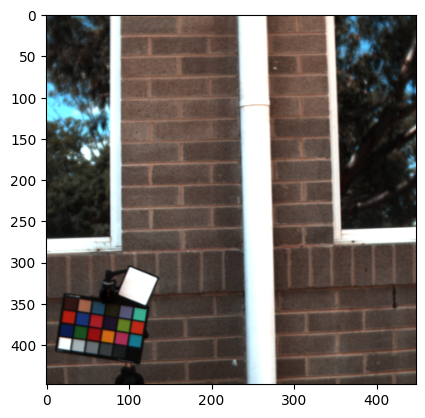

In [38]:
batch, img_names = next(iter(train_loader))
example= batch[0]

print(example.shape, img_names[0])

if num_channels == 51:
    example1_image = extract_rgb(example, 31,13,2)
else:
    example1_image = extract_rgb(example)

plt.imshow(example1_image)
plt.show()

In [39]:
# Clear CUDA memory
torch.cuda.empty_cache()

spectral_model = VariationalAutoencoder()


# need to test SAM loss, BCE loss, etc. 
# recon_loss = SAMLoss()
# recon_loss = torch.nn.MSELoss()
recon_loss = torch.nn.BCELoss(reduction='mean') 

criterion = VAE_Loss(recon_loss)

device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


spectral_model = spectral_model.to(device)
optimizer = torch.optim.AdamW(spectral_model.parameters(),
                             lr = 4e-3,
                            #  weight_decay = 1e-4
                             )
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.8)


epochs = 45
history_loss_train = []
history_loss_val = []
min_val_loss = np.inf
for epoch in range(epochs):
    spectral_model.train()
    for inputs, img_names in train_loader:
        
        inputs = inputs.float().to(device)
        optimizer.zero_grad()
        mu, logvar, latent, outputs = spectral_model(inputs)
        loss = criterion(outputs, inputs, mu, logvar)

        
        loss.backward()
        optimizer.step()
        scheduler.step()

    spectral_model.eval()
    with torch.no_grad():
        for inputs, img_names in test_loader:


            inputs = inputs.float().to(device)
            
            mu, logvar, latent, outputs = spectral_model(inputs)
            val_loss = criterion(outputs, inputs, mu, logvar)
            
            
    history_loss_train.append(loss.item())
    history_loss_val.append(val_loss.item())
    print(f'Epoch {epoch+1}/{epochs}, Loss: {loss.item()}, Test Loss: {val_loss.item()}')

    
    if val_loss < min_val_loss:
        # If it has, save the model and update min_val_loss
        torch.save(spectral_model.state_dict(), '/workspaces/HyperTools/best_model_vae_autoencoder_tests.pt')
        min_val_loss = val_loss

Epoch 1/45, Loss: 725.0554809570312, Test Loss: 293.17742919921875
Epoch 2/45, Loss: 466.9962463378906, Test Loss: 134.6020050048828
Epoch 3/45, Loss: 445.25457763671875, Test Loss: 104.82138061523438
Epoch 4/45, Loss: 248.0084686279297, Test Loss: 94.96786499023438
Epoch 5/45, Loss: 273.16943359375, Test Loss: 92.70518493652344
Epoch 6/45, Loss: 364.2769470214844, Test Loss: 91.68556213378906
Epoch 7/45, Loss: 274.92327880859375, Test Loss: 91.48576354980469
Epoch 8/45, Loss: 236.04595947265625, Test Loss: 91.3998031616211
Epoch 9/45, Loss: 456.5655517578125, Test Loss: 91.36296081542969
Epoch 10/45, Loss: 347.4836730957031, Test Loss: 91.35734558105469
Epoch 11/45, Loss: 264.2925109863281, Test Loss: 91.3538818359375
Epoch 12/45, Loss: 173.2567596435547, Test Loss: 91.35342407226562
Epoch 13/45, Loss: 336.3452453613281, Test Loss: 91.35325622558594
Epoch 14/45, Loss: 376.8213806152344, Test Loss: 91.35322570800781
Epoch 15/45, Loss: 254.72389221191406, Test Loss: 91.35322570800781
Ep

KeyboardInterrupt: 

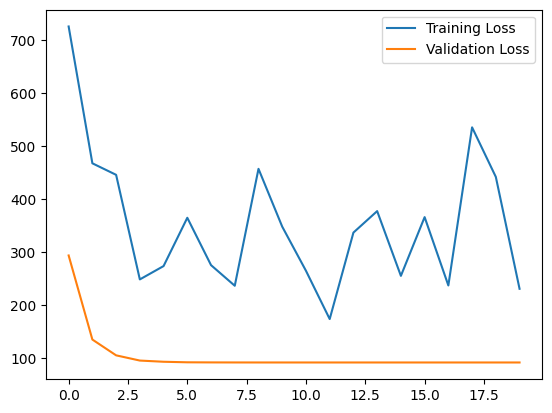

In [40]:
plt.plot(history_loss_train, label="Training Loss")
plt.plot(history_loss_val, label="Validation Loss")
plt.legend()



In [41]:
device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.cuda.empty_cache()

# spectral_model = Autoencoder()
spectral_model = VariationalAutoencoder()
spectral_model.load_state_dict(torch.load('/workspaces/HyperTools/best_model_vae_autoencoder_tests.pt'))
spectral_model = spectral_model.to(device)

(204, 448, 448) (204, 448, 448) torch.Size([2, 3, 448, 448])
(448, 448, 3)
4.55801 -4.729975
0.17268611 -0.08863078


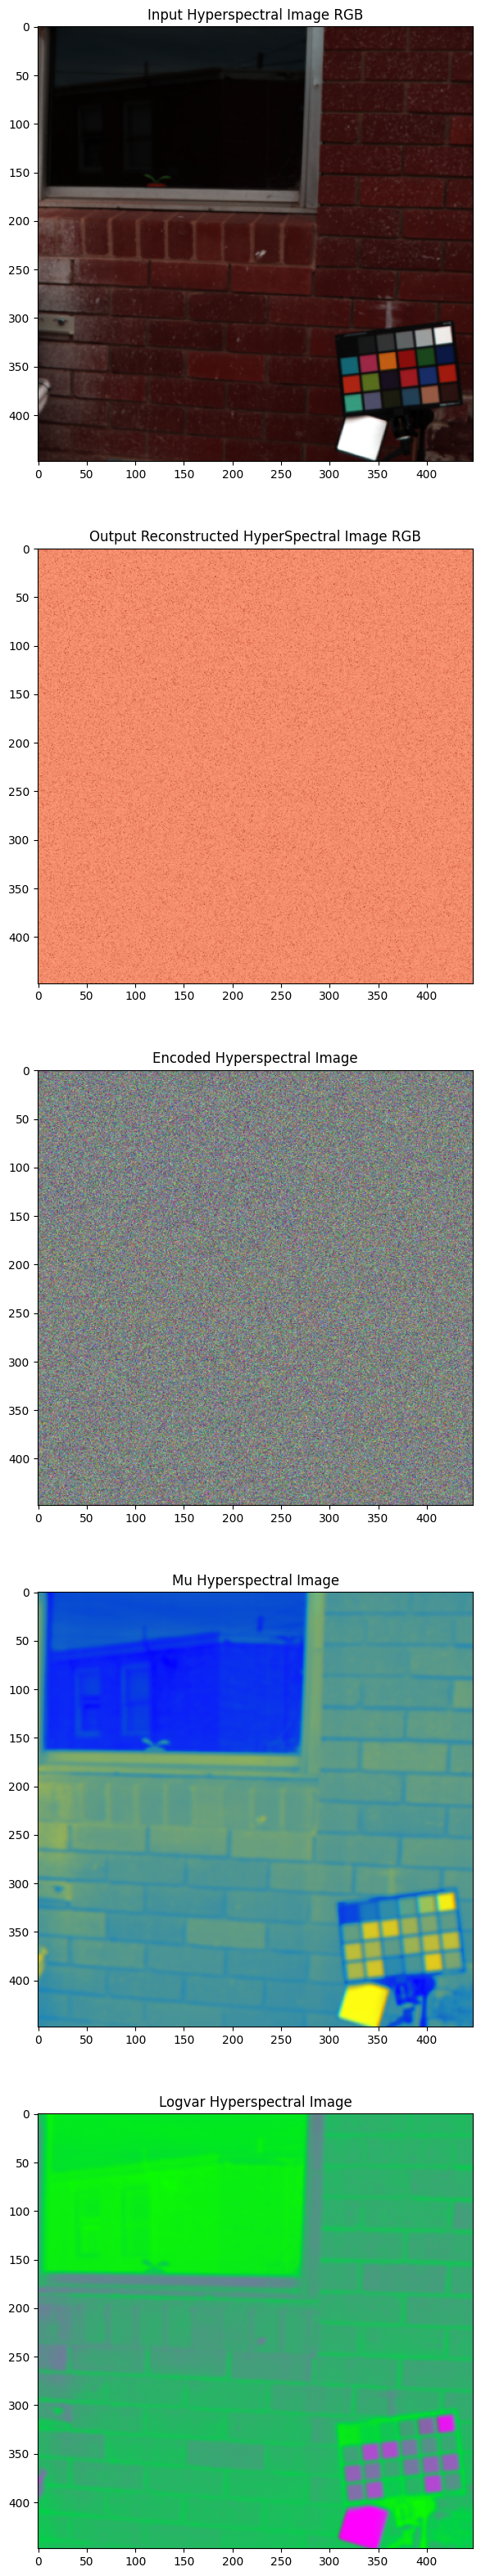

In [42]:
import matplotlib.pyplot as plt



img_num = 0

# # Get a batch of test data
# test_data_iter = iter(test_loader)
# inputs = next(test_data_iter)
# Get the first batch of test data
first_batch, img_names = next(iter(test_loader))

# Select the first item from the batch
first_item = first_batch[img_num]
# Move the inputs to the device
# first_item = first_item.float().to(device)

# print(first_batch.shape, first_item.shape)
first_batch = first_batch.float().to(device)


# Get the model's reconstruction of the inputs
# encoded, outputs = spectral_model(first_batch)
encoded, logvar, latent, outputs = spectral_model(first_batch)
# mu, encoded, outputs = spectral_model(first_batch)

# Move the inputs and outputs to the CPU for plotting
first_item = first_item.cpu()
outputs = outputs.cpu()

# Detach the inputs and outputs from the computation graph
first_item = first_item.detach().numpy()
outputs = outputs[img_num].detach().numpy()

print(first_item.shape, outputs.shape, encoded.shape)

# Transpose the dimensions of the encoded representation
encoded_transposed = np.transpose(latent[img_num].cpu().detach().numpy(), (1, 2, 0))
encoded_transposed_mu = np.transpose(encoded[img_num].cpu().detach().numpy(), (1, 2, 0))
encoded_transposed_logvar = np.transpose(logvar[img_num].cpu().detach().numpy(), (1, 2, 0))

print(encoded_transposed.shape)




if num_channels == 51:
    example_image = extract_rgb(first_item, 31,13,2)
    example_image2 = extract_rgb(outputs, 31,13,2)
else:
    example_image = extract_rgb(first_item)
    example_image2 = extract_rgb(outputs)
    
    

# Initialize an empty array for the normalized data
normalized = np.empty_like(encoded_transposed)

normalized_mu = np.empty_like(encoded_transposed)
normalized_logvar = np.empty_like(encoded_transposed)


# normalized = encoded_transposed
#print max and min of encoded transposed
print(np.max(encoded_transposed), np.min(encoded_transposed))
print(np.max(encoded.cpu().detach().numpy()), np.min(encoded.cpu().detach().numpy()))
# # Iterate over each channel
for i in range(encoded_transposed.shape[2]):
    # Get the current channel
    channel = encoded_transposed[:, :, i]
    channel_mu = encoded_transposed_mu[:, :, i]
    channel_logvar = encoded_transposed_logvar[:, :, i]

    # Normalize the current channel
    normalized_channel = (channel - channel.min()) / (channel.max() - channel.min())
    normalized_channel_mu = (channel_mu - channel_mu.min()) / (channel_mu.max() - channel_mu.min())
    normalized_channel_logvar = (channel_logvar - channel_logvar.min()) / (channel_logvar.max() - channel_logvar.min())

    # Store the normalized channel
    normalized[:, :, i] = normalized_channel
    normalized_mu[:, :, i] = normalized_channel_mu
    normalized_logvar[:, :, i] = normalized_channel_logvar
    
    
    

fig = plt.figure(figsize=(20, 40))

plt.subplot(5, 1, 1)  # 1 row, 3 columns, 1st subplot = image1
plt.imshow(example_image)
plt.title('Input Hyperspectral Image RGB')

plt.subplot(5, 1, 2)  # 1 row, 3 columns, 1st subplot = image1
plt.imshow(example_image2)
plt.title('Output Reconstructed HyperSpectral Image RGB')


plt.subplot(5, 1, 3)  # 1 row, 3 columns, 1st subplot = image1
plt.imshow(normalized)
plt.title('Encoded Hyperspectral Image')

plt.subplot(5, 1, 4)  # 1 row, 3 columns, 1st subplot = image1
plt.imshow(normalized_mu)
plt.title('Mu Hyperspectral Image')


plt.subplot(5, 1, 5)  # 1 row, 3 columns, 1st subplot = image1
plt.imshow(normalized_logvar)
plt.title('Logvar Hyperspectral Image')


plt.show()
